In [ ]:
import os, sys
from google.colab import drive, userdata
drive.mount("/content/drive")
token = userdata.get("GITHUB_TOKEN")
TEAM_REPO = "leomueller5/llm_astar_max"
ORDNER = "/content/drive/MyDrive/llm_astar_max"

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


Table 1 – Reproduction (LLM-A*, GPT-4o mini)
Section A generates the LLM responses (saved in antworten_*.json).
Section B is our first implementation using Dynamic WA* following Pohl (ε = 1) – outdated, kept for documentation only.
Section C is the final computation of Table 1 using Dynamic WA* as described in the paper (page 7: initial weight 2, decay 0.99).

In [ ]:
if not os.path.exists(ORDNER):
    !git clone https://{token}@github.com/{TEAM_REPO}.git {ORDNER}
%cd {ORDNER}
!git config user.name "Jojo"
!git config user.email "deine@email.com"
!git checkout table1 2>/dev/null || git checkout -b table1
!git pull origin main
!mkdir -p table1_reproduction
%cd table1_reproduction
CODE = ORDNER + "/llm-astar"
sys.path.insert(0, CODE)
!ls {CODE}

Cloning into '/content/drive/MyDrive/llm_astar_max'...
remote: Enumerating objects: 1185, done.
remote: Counting objects: 100% (1185/1185), done.
remote: Compressing objects: 100% (1167/1167), done.
remote: Total 1185 (delta 2), reused 1181 (delta 2), pack-reused 0 (from 0)
Receiving objects: 100% (1185/1185), 11.26 MiB | 12.14 MiB/s, done.
Resolving deltas: 100% (2/2), done.
Updating files: 100% (2108/2108), done.
/content/drive/MyDrive/llm_astar_max
Switched to a new branch 'table1'
From https://github.com/leomueller5/llm_astar_max
 * branch            main       -> FETCH_HEAD
Already up to date.
/content/drive/MyDrive/llm_astar_max/table1_reproduction
dataset  docs  LICENSE	llmastar  README.md  requirements.txt  setup.py  tests


In [ ]:
!pip install -q openai shapely

In [ ]:
os.environ["OPEN_API_KEY"] = userdata.get("OPENAI_API_KEY")
os.environ["LLM_MODEL"] = "gpt-4o-mini"

In [ ]:
os.environ["OPENAI_API_KEY"] = userdata.get("OPENAI_API_KEY")
key = os.environ["OPENAI_API_KEY"]
print("Key geladen:", key.startswith("sk-"), "| Länge:", len(key))

Key geladen: True | Länge: 164


In [ ]:
from openai import OpenAI

client = OpenAI(max_retries=5)
MODEL = "gpt-4o-mini"

def frage_gpt(text):
    antwort = client.chat.completions.create(
        model=MODEL,
        messages=[{"role": "user", "content": text}],
        temperature=0,
        max_tokens=1000,
    )
    return antwort.choices[0].message.content or ""

print(frage_gpt("Antworte nur mit: Hallo"))

Hallo


First Test A*

{'start': [5, 5], 'goal': [27, 15], 'size': [51, 31], 'horizontal_barriers': [[10, 0, 25], [15, 30, 50]], 'vertical_barriers': [[25, 10, 22]], 'range_x': [0, 51], 'range_y': [0, 31]}
{'operation': 218, 'storage': 237, 'length': 28.48528137423857}


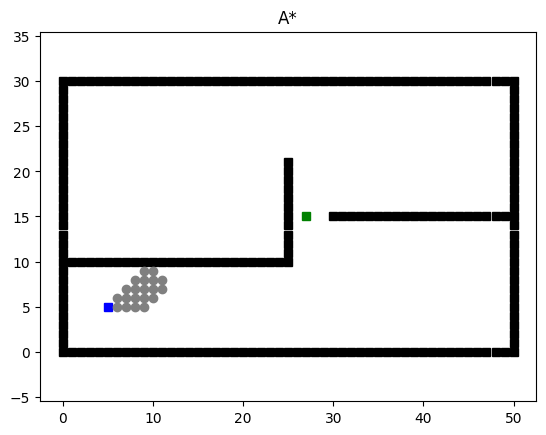

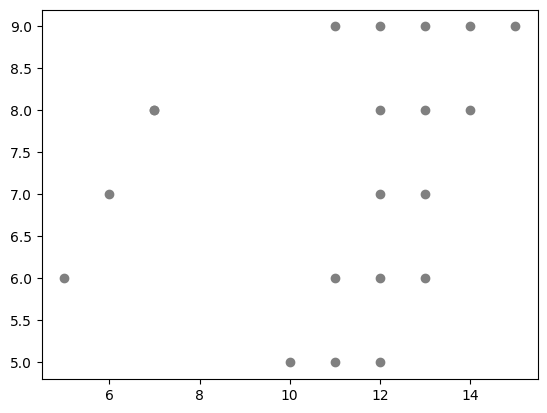

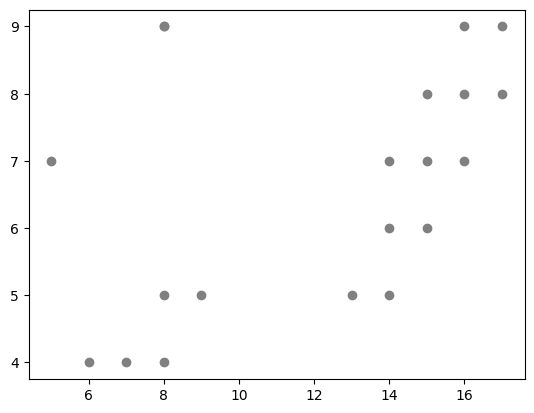

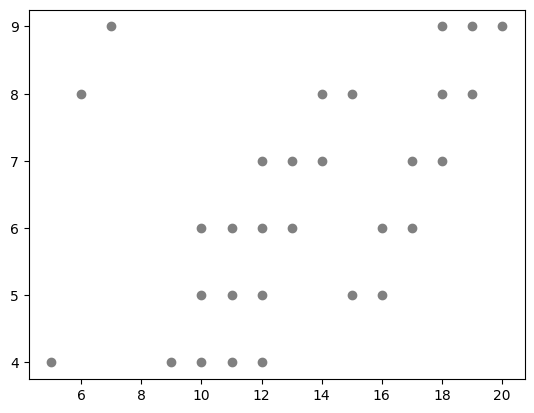

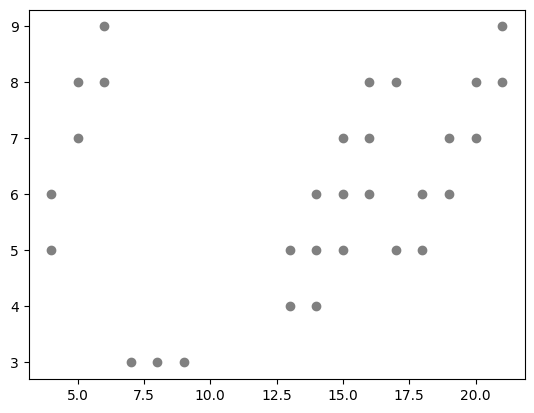

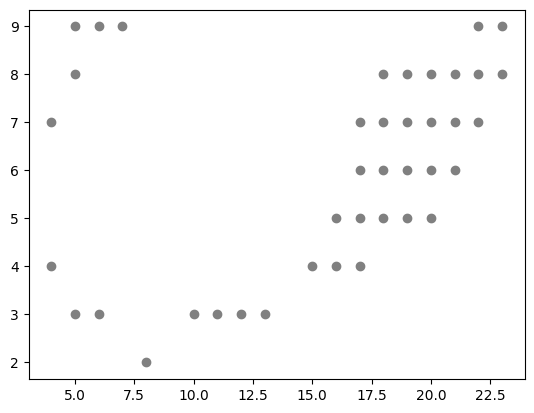

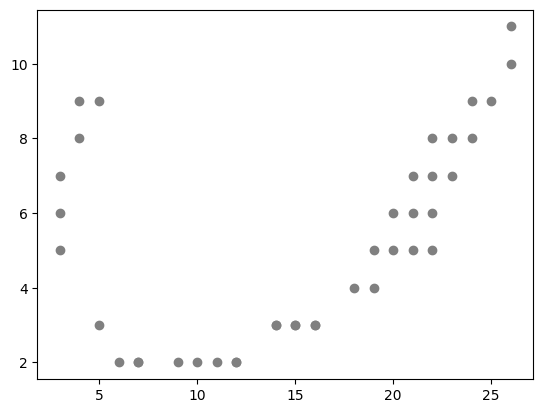

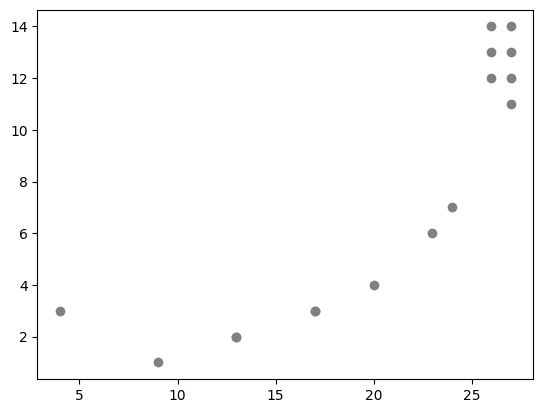

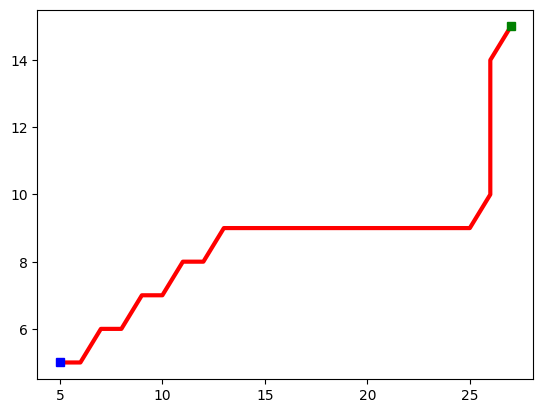

<Figure size 640x480 with 0 Axes>

{'operation': 218, 'storage': 237, 'length': 28.48528137423857}


In [ ]:
import copy
from llmastar.pather import AStar, LLMAStar

query = {"start": [5, 5], "goal": [27, 15], "size": [51, 31],
         "horizontal_barriers": [[10, 0, 25], [15, 30, 50]],   # [y, x_start, x_end]
         "vertical_barriers": [[25, 10, 22]],                   # [x, y_start, y_end]
         "range_x": [0, 51], "range_y": [0, 31]}

ergebnis = AStar().searching(query=copy.deepcopy(query), filepath="astar.png")
print(ergebnis)

First Test: LLM-A*

LLM-Antwort: To find a path from the start point [5, 5] to the goal point [27, 15] while navigating around the specified obstacles, we need to consider the horizontal and vertical barriers.

### Given:
- **Start Point:** [5, 5]
- **Goal Point:** [27, 15]
- **Horizontal Barriers:** 
  - [10, 0, 25] (y = 10 from x = 0 to x = 25)
  - [15, 30, 50] (y = 15 from x = 30 to x = 50)
- **Vertical Barriers:** 
  - [25, 10, 22] (x = 25 from y = 10 to y = 22)

### Analysis:
1. The horizontal barrier at y = 10 prevents movement directly upwards from y = 5 to y = 10.
2. The vertical barrier at x = 25 prevents movement directly to the right from x = 25 between y = 10 and y = 22.
3. The goal point is at (27, 15), which is above the horizontal barrier at y = 10 and to the right of the vertical barrier at x = 25.

### Pathfinding:
To navigate around the barriers, we can take the following steps:
1. Move right to (10, 5).
2. Move up to (10, 10) to avoid the horizontal barrier.
3. Move right to (20, 10).
4

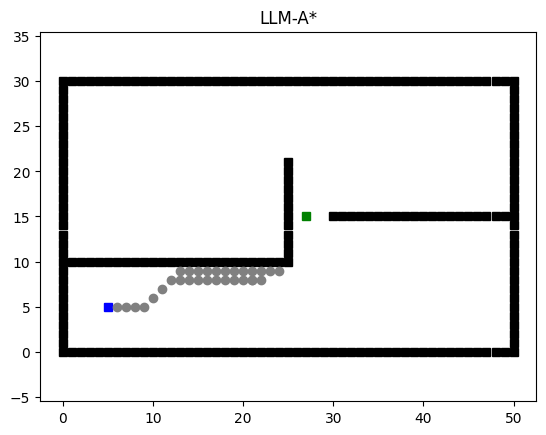

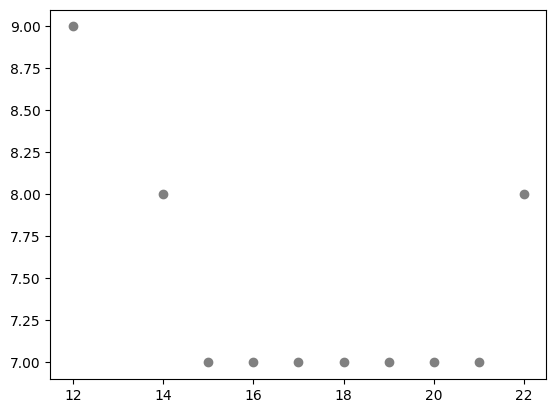

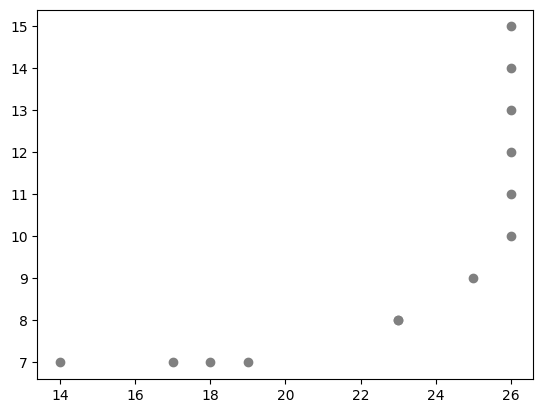

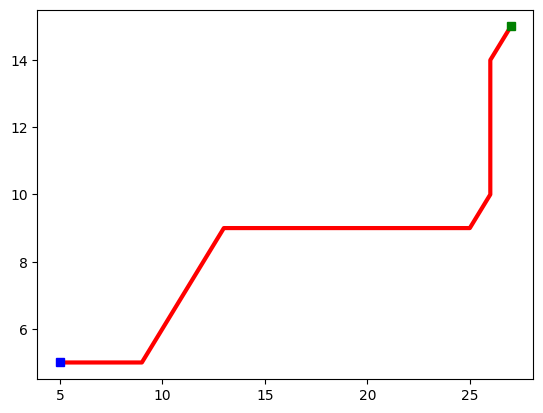

<Figure size 640x480 with 0 Axes>

{'operation': 55, 'storage': 119, 'length': 28.48528137423857, 'llm_output': [(5, 5), (10, 5), (20, 15), (27, 15)]}


In [ ]:
from llmastar.pather.llm_a_star.prompt import gpt_prompt

def baue_prompt(query, prompt_typ):
    return gpt_prompt[prompt_typ].format(
        start=query["start"], goal=query["goal"],
        horizontal_barriers=query["horizontal_barriers"],
        vertical_barriers=query["vertical_barriers"])

class FesteAntwort:
    def __init__(self, antwort):
        self.antwort = antwort
    def ask(self, *args, **kwargs):
        return self.antwort

antwort = frage_gpt(baue_prompt(query, "standard"))
print("LLM-Antwort:", antwort)

planner = LLMAStar(llm="gpt", prompt="standard")
planner.model = FesteAntwort(antwort)
ergebnis = planner.searching(query=copy.deepcopy(query), filepath="llm.png")
print(ergebnis)

Tabel 1

In [ ]:
Section B – first implementation (outdated). We later corrected this variant, see Section C

Data

In [ ]:
import json

with open(CODE + "/dataset/environment_50_30.json") as f:
    karten = json.load(f)

samples = []
for karte in karten:
    for k, (start, ziel, text) in enumerate(karte["start_goal"]):
        samples.append({"id": f"{karte['id']}_{k}",
            "query": {"start": start, "goal": ziel, "size": [51, 31],
                      "horizontal_barriers": karte["horizontal_barriers"],
                      "vertical_barriers": karte["vertical_barriers"],
                      "range_x": karte["range_x"], "range_y": karte["range_y"]}})
print(len(samples))   # muss 1000 sein

1000


In [ ]:
import io, contextlib
from llmastar.env.search import plotting
plotting.Plotting.animation = lambda self, *args, **kwargs: None

def leise(funktion):
    with contextlib.redirect_stdout(io.StringIO()):
        return funktion()

In [ ]:
from concurrent.futures import ThreadPoolExecutor

PROMPTS = ["standard", "cot", "repe"]

def frage_llm(query, prompt_typ):
    return frage_gpt(baue_prompt(query, prompt_typ))

def hole_antworten(prompt_typ, beispiele):
    datei = f"antworten_{prompt_typ}.json"
    antworten = json.load(open(datei)) if os.path.exists(datei) else {}
    offen = [s for s in beispiele if s["id"] not in antworten]
    print(prompt_typ, ": schon da", len(antworten), "| noch offen", len(offen))
    def arbeit(s):
        try:
            return s["id"], frage_llm(s["query"], prompt_typ)
        except Exception as fehler:
            print("Fehler bei", s["id"], fehler)
            return s["id"], None
    with ThreadPoolExecutor(max_workers=8) as pool:
        for i, (sid, antwort) in enumerate(pool.map(arbeit, offen), 1):
            if antwort is not None:
                antworten[sid] = antwort
            if i % 50 == 0:
                json.dump(antworten, open(datei, "w"))
                print(prompt_typ, i, "/", len(offen))
    json.dump(antworten, open(datei, "w"))
    return antworten

Now the test run with 20 examples, evenly spread across all cards (every 50th example):

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

In [ ]:
def llm_astar_mit_antwort(query, prompt_typ, antwort):
    planner = LLMAStar(llm="gpt", prompt=prompt_typ)
    planner.model = FesteAntwort(antwort)
    return planner.searching(query=copy.deepcopy(query))

In [ ]:
import math
from llmastar.utils import list_parse, is_lines_collision

def segment_trifft_wand(p, q, query):
    B = query["range_x"][1] - 1
    H = query["range_y"][1] - 1
    waende = [[[h[1], h[0]], [h[2], h[0]]] for h in query["horizontal_barriers"]]
    waende += [[[v[0], v[1]], [v[0], v[2]]] for v in query["vertical_barriers"]]
    waende += [[[0, 0], [B, 0]], [[0, H], [B, H]], [[0, 0], [0, H]], [[B, 0], [B, H]]]
    return any(is_lines_collision([p, q], w) for w in waende)

def pruefe_llm_only(query, antwort):
    pfad = list_parse(antwort or "")
    if not isinstance(pfad, list) or len(pfad) < 2:
        return False, None
    try:
        pfad = [(float(p[0]), float(p[1])) for p in pfad]
    except Exception:
        return False, None
    if list(pfad[0]) != list(query["start"]) or list(pfad[-1]) != list(query["goal"]):
        return False, None
    for a, b in zip(pfad, pfad[1:]):
        if segment_trifft_wand(a, b, query):
            return False, None
    return True, sum(math.dist(a, b) for a, b in zip(pfad, pfad[1:]))

print(pruefe_llm_only(query, "Generated Path: [[5, 5], [27, 15]]"))            # (False, None): Linie durch die Wand
print(pruefe_llm_only(query, "Generated Path: [[5, 5], [26, 9], [27, 15]]"))  # (True, 27.46)

(False, None)
(True, 27.460320856730167)


In [ ]:
import heapq

class WeightedAStar(AStar):
    """Dynamic WA* nach Paper: Startgewicht 2, x0.99 pro untersuchtem Feld, mindestens 1.
       Die Warteliste wird nach jedem untersuchten Feld neu bewertet."""
    def gewicht(self):
        return max(1.0, 2.0 * 0.99 ** len(self.CLOSED))
    def f_value(self, s):
        return self.g[s] + self.gewicht() * self.heuristic(s)
    def get_neighbor(self, s):
        # wird einmal pro untersuchtem Feld aufgerufen -> hier die Warteliste neu bewerten
        self.OPEN = [(self.f_value(n), n) for _, n in self.OPEN]
        heapq.heapify(self.OPEN)
        return super().get_neighbor(s)


In [ ]:
zeilen = []
for i, s in enumerate(beispiele):
    q = s["query"]
    if any(s["id"] not in antworten[pt] for pt in PROMPTS):
        continue   # Antwort fehlt noch -> Schritt 9 nochmal ausführen
    a = leise(lambda: AStar().searching(query=copy.deepcopy(q)))
    w = leise(lambda: WeightedAStar().searching(query=copy.deepcopy(q)))
    zeile = {"id": s["id"],
             "astar_op": a["operation"], "astar_st": a["storage"], "astar_len": a["length"],
             "wa_op": w["operation"], "wa_st": w["storage"], "wa_len": w["length"]}
    for pt in PROMPTS:
        antwort = antworten[pt][s["id"]]
        try:
            r = leise(lambda: llm_astar_mit_antwort(q, pt, antwort))
        except Exception:
            r = leise(lambda: llm_astar_mit_antwort(q, pt, ""))   # unlesbare Antwort -> ohne Wegpunkte
        gueltig, laenge = pruefe_llm_only(q, antwort)
        zeile.update({f"{pt}_op": r["operation"], f"{pt}_st": r["storage"], f"{pt}_len": r["length"],
                      f"{pt}_only_valid": gueltig, f"{pt}_only_len": laenge})
    zeilen.append(zeile)
    if (i + 1) % 100 == 0:
        print(i + 1, "von", len(beispiele))

json.dump(zeilen, open("ergebnisse.json", "w"))

In [ ]:
import numpy as np
import pandas as pd

df = pd.DataFrame(json.load(open("ergebnisse.json")))

def gm(verhaeltnisse):
    return 100 * np.exp(np.log(np.asarray(verhaeltnisse, dtype=float)).mean())

tabelle = [
    {"Methode": "A*", "Prompt": "-", "Operation %": 100, "Storage %": 100, "Länge %": 100, "Valid %": 100},
    {"Methode": "Weighted A*", "Prompt": "-", "Operation %": gm(df.wa_op / df.astar_op),
     "Storage %": gm(df.wa_st / df.astar_st), "Länge %": gm(df.wa_len / df.astar_len), "Valid %": 100}]
for pt in PROMPTS:
    ok = df[f"{pt}_only_valid"].astype(bool)
    tabelle.append({"Methode": "LLM-only", "Prompt": pt, "Operation %": None, "Storage %": None,
        "Länge %": gm(df.loc[ok, f"{pt}_only_len"] / df.loc[ok, "astar_len"]) if ok.any() else None,
        "Valid %": 100 * ok.mean()})
for pt in PROMPTS:
    tabelle.append({"Methode": "LLM-A*", "Prompt": pt,
        "Operation %": gm(df[f"{pt}_op"] / df.astar_op), "Storage %": gm(df[f"{pt}_st"] / df.astar_st),
        "Länge %": gm(df[f"{pt}_len"] / df.astar_len), "Valid %": 100 * np.isfinite(df[f"{pt}_len"]).mean()})

ergebnis_tabelle = pd.DataFrame(tabelle).round(2)
ergebnis_tabelle.to_csv("table1.csv", index=False)
ergebnis_tabelle

,Methode,Prompt,Operation %,Storage %,Länge %,Valid %
0,A*,-,100.00,100.00,100.00,100.0
1,Weighted A*,-,38.53,60.25,104.39,100.0
2,LLM-only,standard,NaN,NaN,118.51,5.0
3,LLM-only,cot,NaN,NaN,120.10,5.0
4,LLM-only,repe,NaN,NaN,112.91,5.0
5,LLM-A*,standard,54.30,69.17,103.09,100.0
6,LLM-A*,cot,50.67,67.23,102.58,100.0
7,LLM-A*,repe,54.92,69.41,101.20,100.0


Big run

In [ ]:
beispiele = samples   # alle 1000
antworten = {pt: hole_antworten(pt, beispiele) for pt in PROMPTS}

standard : schon da 20 | noch offen 980
standard 50 / 980
standard 100 / 980
standard 150 / 980
standard 200 / 980
standard 250 / 980
standard 300 / 980
standard 350 / 980
standard 400 / 980
standard 450 / 980
standard 500 / 980
standard 550 / 980
standard 600 / 980
standard 650 / 980
standard 700 / 980
standard 750 / 980
standard 800 / 980
standard 850 / 980
standard 900 / 980
standard 950 / 980
cot : schon da 20 | noch offen 980
cot 50 / 980
cot 100 / 980
cot 150 / 980
cot 200 / 980
cot 250 / 980
cot 300 / 980
cot 350 / 980
cot 400 / 980
cot 450 / 980
cot 500 / 980
cot 550 / 980
cot 600 / 980
cot 650 / 980
cot 700 / 980
cot 750 / 980
cot 800 / 980
cot 850 / 980
cot 900 / 980
cot 950 / 980
repe : schon da 20 | noch offen 980
repe 50 / 980
repe 100 / 980
repe 150 / 980
repe 200 / 980
repe 250 / 980
repe 300 / 980
repe 350 / 980
repe 400 / 980
repe 450 / 980
repe 500 / 980
repe 550 / 980
repe 600 / 980
repe 650 / 980
repe 700 / 980
repe 750 / 980
repe 800 / 980
repe 850 / 980
repe 900 /

In [ ]:
for pt in PROMPTS:
    print(pt, ":", len(antworten[pt]), "von", len(beispiele))

standard : 1000 von 1000
cot : 1000 von 1000
repe : 1000 von 1000


In [ ]:
zeilen = []
for i, s in enumerate(beispiele):
    q = s["query"]
    if any(s["id"] not in antworten[pt] for pt in PROMPTS):
        continue   # Antwort fehlt noch -> Zelle 1 nochmal ausführen
    a = leise(lambda: AStar().searching(query=copy.deepcopy(q)))
    w = leise(lambda: WeightedAStar().searching(query=copy.deepcopy(q)))
    zeile = {"id": s["id"],
             "astar_op": a["operation"], "astar_st": a["storage"], "astar_len": a["length"],
             "wa_op": w["operation"], "wa_st": w["storage"], "wa_len": w["length"]}
    for pt in PROMPTS:
        antwort = antworten[pt][s["id"]]
        try:
            r = leise(lambda: llm_astar_mit_antwort(q, pt, antwort))
        except Exception:
            r = leise(lambda: llm_astar_mit_antwort(q, pt, ""))   # unlesbare Antwort -> ohne Wegpunkte
        gueltig, laenge = pruefe_llm_only(q, antwort)
        zeile.update({f"{pt}_op": r["operation"], f"{pt}_st": r["storage"], f"{pt}_len": r["length"],
                      f"{pt}_only_valid": gueltig, f"{pt}_only_len": laenge})
    zeilen.append(zeile)
    if (i + 1) % 100 == 0:
        print(i + 1, "von", len(beispiele))

json.dump(zeilen, open("ergebnisse.json", "w"))
print("Fertig:", len(zeilen), "Beispiele gespeichert")

100 von 1000
200 von 1000
300 von 1000
400 von 1000
500 von 1000
600 von 1000
700 von 1000
800 von 1000
900 von 1000
1000 von 1000
Fertig: 1000 Beispiele gespeichert


In [ ]:
df = pd.DataFrame(json.load(open("ergebnisse.json")))

tabelle = [
    {"Methode": "A*", "Prompt": "-", "Operation %": 100, "Storage %": 100, "Länge %": 100, "Valid %": 100},
    {"Methode": "Weighted A*", "Prompt": "-", "Operation %": gm(df.wa_op / df.astar_op),
     "Storage %": gm(df.wa_st / df.astar_st), "Länge %": gm(df.wa_len / df.astar_len), "Valid %": 100}]
for pt in PROMPTS:
    ok = df[f"{pt}_only_valid"].astype(bool)
    tabelle.append({"Methode": "LLM-only", "Prompt": pt, "Operation %": None, "Storage %": None,
        "Länge %": gm(df.loc[ok, f"{pt}_only_len"] / df.loc[ok, "astar_len"]) if ok.any() else None,
        "Valid %": 100 * ok.mean()})
for pt in PROMPTS:
    tabelle.append({"Methode": "LLM-A*", "Prompt": pt,
        "Operation %": gm(df[f"{pt}_op"] / df.astar_op), "Storage %": gm(df[f"{pt}_st"] / df.astar_st),
        "Länge %": gm(df[f"{pt}_len"] / df.astar_len), "Valid %": 100 * np.isfinite(df[f"{pt}_len"]).mean()})

ergebnis_tabelle = pd.DataFrame(tabelle).round(2)
ergebnis_tabelle.to_csv("table1.csv", index=False)
ergebnis_tabelle

,Methode,Prompt,Operation %,Storage %,Länge %,Valid %
0,A*,-,100.00,100.00,100.00,100.0
1,Weighted A*,-,35.90,58.49,104.12,100.0
2,LLM-only,standard,NaN,NaN,119.38,6.8
3,LLM-only,cot,NaN,NaN,124.20,6.2
4,LLM-only,repe,NaN,NaN,117.33,9.9
5,LLM-A*,standard,46.09,65.40,102.74,100.0
6,LLM-A*,cot,47.61,66.24,102.61,100.0
7,LLM-A*,repe,50.13,68.31,102.30,100.0


In [ ]:
def frage_gpt_abgeschnitten(text):
    a = client.chat.completions.create(model=MODEL, messages=[{"role": "user", "content": text}],
                                       temperature=0, max_tokens=1000, stop=["\n"])
    return a.choices[0].message.content or ""

test = samples[::10]   # 100 Beispiele, über alle Karten verteilt
abgeschnitten = {}
with ThreadPoolExecutor(max_workers=8) as pool:
    for sid, ant in pool.map(lambda s: (s["id"], frage_gpt_abgeschnitten(baue_prompt(s["query"], "cot"))), test):
        abgeschnitten[sid] = ant
json.dump(abgeschnitten, open("antworten_cot_abgeschnitten.json", "w"))

astar_ops = dict(zip(df.id, df.astar_op))
voll_ops = dict(zip(df.id, df.cot_op))
r_ab, r_voll = [], []
for s in test:
    try:
        r = leise(lambda: llm_astar_mit_antwort(s["query"], "cot", abgeschnitten[s["id"]]))
    except Exception:
        r = leise(lambda: llm_astar_mit_antwort(s["query"], "cot", ""))
    r_ab.append(r["operation"] / astar_ops[s["id"]])
    r_voll.append(voll_ops[s["id"]] / astar_ops[s["id"]])

print("CoT abgeschnitten :", round(gm(r_ab), 2), "% Operationen")
print("CoT vollständig   :", round(gm(r_voll), 2), "% Operationen")
print("Beispiel-Antwort  :", list(abgeschnitten.values())[0])

CoT abgeschnitten : 35.06 % Operationen
CoT vollständig   : 48.17 % Operationen
Beispiel-Antwort  : To find a path from the start point [5, 5] to the goal point [20, 20], we need to navigate around the given horizontal and vertical barriers.


In [ ]:
astar_len = dict(zip(df.id, df.astar_len))
voll_len = dict(zip(df.id, df.cot_len))
l_ab, l_voll, mit_pfad = [], [], 0
for s in test:
    ant = abgeschnitten[s["id"]]
    if "[[" in ant:
        mit_pfad += 1
    try:
        r = leise(lambda: llm_astar_mit_antwort(s["query"], "cot", ant))
    except Exception:
        r = leise(lambda: llm_astar_mit_antwort(s["query"], "cot", ""))
    l_ab.append(r["length"] / astar_len[s["id"]])
    l_voll.append(voll_len[s["id"]] / astar_len[s["id"]])

print("Antworten mit Pfad (abgeschnitten):", mit_pfad, "von", len(test))
print("Länge abgeschnitten :", round(gm(l_ab), 2), "%")
print("Länge vollständig   :", round(gm(l_voll), 2), "%")

Antworten mit Pfad (abgeschnitten): 0 von 100
Länge abgeschnitten : 102.63 %
Länge vollständig   : 102.38 %


In [ ]:
%cd {ORDNER}
!git branch --show-current

/content/drive/MyDrive/llm_astar_max
table1


In [ ]:
!git pull --no-edit origin main

From https://github.com/leomueller5/llm_astar_max
 * branch            main       -> FETCH_HEAD
Already up to date.


In [ ]:
!git status

On branch table1
Untracked files:
  (use "git add <file>..." to include in what will be committed)
	table1_reproduction/

nothing added to commit but untracked files present (use "git add" to track)


In [ ]:
!grep -rln "sk-" --include="*.py" --include="*.json" --include="*.ipynb" table1_reproduction || echo "Kein Key gefunden - gut"

Kein Key gefunden - gut


In [ ]:
%cd {ORDNER}/table1_reproduction
!git add .
!git commit -m "Table 1 reproduction with gpt-4o-mini on 1000 samples (original llm-astar untouched)"

/content/drive/MyDrive/llm_astar_max/table1_reproduction
[table1 003cee6] Table 1 reproduction with gpt-4o-mini on 1000 samples (original llm-astar untouched)
 8 files changed, 14 insertions(+)
 create mode 100644 table1_reproduction/antworten_cot.json
 create mode 100644 table1_reproduction/antworten_cot_abgeschnitten.json
 create mode 100644 table1_reproduction/antworten_repe.json
 create mode 100644 table1_reproduction/antworten_standard.json
 create mode 100644 table1_reproduction/astar.png
 create mode 100644 table1_reproduction/ergebnisse.json
 create mode 100644 table1_reproduction/llm.png
 create mode 100644 table1_reproduction/table1.csv


In [ ]:
!git diff --stat origin/main

 table1_reproduction/antworten_cot.json               |   1 +
 table1_reproduction/antworten_cot_abgeschnitten.json |   1 +
 table1_reproduction/antworten_repe.json              |   1 +
 table1_reproduction/antworten_standard.json          |   1 +
 table1_reproduction/astar.png                        | Bin 0 -> 2397 bytes
 table1_reproduction/ergebnisse.json                  |   1 +
 table1_reproduction/llm.png                          | Bin 0 -> 2397 bytes
 table1_reproduction/table1.csv                       |   9 +++++++++
 8 files changed, 14 insertions(+)


In [ ]:
!git push -u origin table1

Enumerating objects: 11, done.
Counting objects: 100% (11/11), done.
Delta compression using up to 2 threads
Compressing objects: 100% (10/10), done.
Writing objects: 100% (10/10), 643.35 KiB | 3.01 MiB/s, done.
Total 10 (delta 1), reused 0 (delta 0), pack-reused 0
remote: Resolving deltas: 100% (1/1), completed with 1 local object.
remote: 
remote: Create a pull request for 'table1' on GitHub by visiting:
remote:      https://github.com/leomueller5/llm_astar_max/pull/new/table1
remote: 
To https://github.com/leomueller5/llm_astar_max.git
 * [new branch]      table1 -> table1
branch 'table1' set up to track 'origin/table1'.


In [ ]:
from google.colab import drive
drive.mount("/content/drive")

import os
ORDNER = "/content/drive/MyDrive/llm_astar_max"
pfad = f"{ORDNER}/table1_reproduction"
print("Ordner gefunden:", os.path.exists(pfad))
!ls {pfad}


Mounted at /content/drive
Ordner gefunden: True
antworten_cot_abgeschnitten.json  antworten_standard.json  llm.png
antworten_cot.json		  astar.png		   table1.csv
antworten_repe.json		  ergebnisse.json


In [ ]:
import pandas as pd

ORDNER = "/content/drive/MyDrive/llm_astar_max"
pfad = f"{ORDNER}/table1_reproduction"
t = pd.read_csv(f"{pfad}/table1.csv")

prompt_namen = {"standard": "Few-shot", "cot": "CoT", "repe": "RePE", "-": "-"}
methoden_namen = {"A*": "A*", "Weighted A*": "Dynamic WA*",
                  "LLM-only": "LLM-only", "LLM-A*": "LLM-A*"}

paper_format = pd.DataFrame({
    "Method": t["Methode"].map(methoden_namen),
    "Base Model": ["-", "-"] + ["GPT-4o mini"] * 6,
    "Prompt": t["Prompt"].map(prompt_namen),
    "Operation Ratio (%) ↓": t["Operation %"],
    "Storage Ratio (%) ↓": t["Storage %"],
    "Relative Path Length (%) ↓": t["Länge %"],
    "Valid Path Ratio (%) ↑": t["Valid %"],
})

paper_format.to_csv(f"{pfad}/table1_paperformat.csv", index=False)
paper_format.style.format(precision=2, na_rep="-").hide(axis="index")


Method,Base Model,Prompt,Operation Ratio (%) ↓,Storage Ratio (%) ↓,Relative Path Length (%) ↓,Valid Path Ratio (%) ↑
A*,-,-,100.00,100.00,100.00,100.00
Dynamic WA*,-,-,35.90,58.49,104.12,100.00
LLM-only,GPT-4o mini,Few-shot,-,-,119.38,6.80
LLM-only,GPT-4o mini,CoT,-,-,124.20,6.20
LLM-only,GPT-4o mini,RePE,-,-,117.33,9.90
LLM-A*,GPT-4o mini,Few-shot,46.09,65.40,102.74,100.00
LLM-A*,GPT-4o mini,CoT,47.61,66.24,102.61,100.00
LLM-A*,GPT-4o mini,RePE,50.13,68.31,102.30,100.00


In [ ]:
%cd {pfad}
!git add table1_paperformat.csv
!git commit -m "Add Table 1 in paper format"
!git push


/content/drive/MyDrive/llm_astar_max/table1_reproduction
[table1 c31cae6] Add Table 1 in paper format
 1 file changed, 9 insertions(+)
 create mode 100644 table1_reproduction/table1_paperformat.csv
Enumerating objects: 6, done.
Counting objects: 100% (6/6), done.
Delta compression using up to 2 threads
Compressing objects: 100% (4/4), done.
Writing objects: 100% (4/4), 592 bytes | 118.00 KiB/s, done.
Total 4 (delta 2), reused 0 (delta 0), pack-reused 0
remote: Resolving deltas: 100% (2/2), completed with 2 local objects.
To https://github.com/leomueller5/llm_astar_max.git
   003cee6..c31cae6  table1 -> table1


Section C – final computation of Table 1. Loads the saved LLM responses (no new API calls) and recomputes all rows.

In [ ]:
# ===== Table 1 komplett neu berechnen (KEINE API-Anfragen, kostenlos) =====
import os, sys, json, math, copy, io, contextlib, heapq
import numpy as np, pandas as pd
from google.colab import drive
drive.mount("/content/drive")

ORDNER = "/content/drive/MyDrive/llm_astar_max"
pfad = f"{ORDNER}/table1_reproduction"
CODE = ORDNER + "/llm-astar"
sys.path.insert(0, CODE)
os.chdir(pfad)

from llmastar.env.search import plotting
plotting.Plotting.animation = lambda self, *args, **kwargs: None
from llmastar.pather import AStar, LLMAStar
from llmastar.utils import list_parse, is_lines_collision

# --- Datensatz
karten = json.load(open(CODE + "/dataset/environment_50_30.json"))
samples = []
for karte in karten:
    for k, (start, ziel, text) in enumerate(karte["start_goal"]):
        samples.append({"id": f"{karte['id']}_{k}",
            "query": {"start": start, "goal": ziel, "size": [51, 31],
                      "horizontal_barriers": karte["horizontal_barriers"],
                      "vertical_barriers": karte["vertical_barriers"],
                      "range_x": karte["range_x"], "range_y": karte["range_y"]}})

# --- gespeicherte LLM-Antworten laden (es wird NICHTS neu abgefragt)
PROMPTS = ["standard", "cot", "repe"]
antworten = {pt: json.load(open(f"antworten_{pt}.json")) for pt in PROMPTS}
for pt in PROMPTS:
    print(pt, ":", len(antworten[pt]), "gespeicherte Antworten")

# --- Hilfsfunktionen
def leise(funktion):
    with contextlib.redirect_stdout(io.StringIO()):
        return funktion()

class FesteAntwort:
    def __init__(self, antwort):
        self.antwort = antwort
    def ask(self, *args, **kwargs):
        return self.antwort

def llm_astar_mit_antwort(query, prompt_typ, antwort):
    planner = LLMAStar(llm="gpt", prompt=prompt_typ)
    planner.model = FesteAntwort(antwort)
    return planner.searching(query=copy.deepcopy(query))

def segment_trifft_wand(p, q, query):
    B = query["range_x"][1] - 1
    H = query["range_y"][1] - 1
    waende = [[[h[1], h[0]], [h[2], h[0]]] for h in query["horizontal_barriers"]]
    waende += [[[v[0], v[1]], [v[0], v[2]]] for v in query["vertical_barriers"]]
    waende += [[[0, 0], [B, 0]], [[0, H], [B, H]], [[0, 0], [0, H]], [[B, 0], [B, H]]]
    return any(is_lines_collision([p, q], w) for w in waende)

def pruefe_llm_only(query, antwort):
    weg = list_parse(antwort or "")
    if not isinstance(weg, list) or len(weg) < 2:
        return False, None
    try:
        weg = [(float(p[0]), float(p[1])) for p in weg]
    except Exception:
        return False, None
    if list(weg[0]) != list(query["start"]) or list(weg[-1]) != list(query["goal"]):
        return False, None
    for a, b in zip(weg, weg[1:]):
        if segment_trifft_wand(a, b, query):
            return False, None
    return True, sum(math.dist(a, b) for a, b in zip(weg, weg[1:]))

# --- Dynamic WA* wie im Paper (Startgewicht 2, x0.99 pro untersuchtem Feld)
class WeightedAStar(AStar):
    def gewicht(self):
        return max(1.0, 2.0 * 0.99 ** len(self.CLOSED))
    def f_value(self, s):
        return self.g[s] + self.gewicht() * self.heuristic(s)
    def get_neighbor(self, s):
        self.OPEN = [(self.f_value(n), n) for _, n in self.OPEN]
        heapq.heapify(self.OPEN)
        return super().get_neighbor(s)

# --- alle Suchen
zeilen = []
for i, s in enumerate(samples):
    q = s["query"]
    if any(s["id"] not in antworten[pt] for pt in PROMPTS):
        continue
    a = leise(lambda: AStar().searching(query=copy.deepcopy(q)))
    w = leise(lambda: WeightedAStar().searching(query=copy.deepcopy(q)))
    zeile = {"id": s["id"],
             "astar_op": a["operation"], "astar_st": a["storage"], "astar_len": a["length"],
             "wa_op": w["operation"], "wa_st": w["storage"], "wa_len": w["length"]}
    for pt in PROMPTS:
        antwort = antworten[pt][s["id"]]
        try:
            r = leise(lambda: llm_astar_mit_antwort(q, pt, antwort))
        except Exception:
            r = leise(lambda: llm_astar_mit_antwort(q, pt, ""))
        gueltig, laenge = pruefe_llm_only(q, antwort)
        zeile.update({f"{pt}_op": r["operation"], f"{pt}_st": r["storage"], f"{pt}_len": r["length"],
                      f"{pt}_only_valid": gueltig, f"{pt}_only_len": laenge})
    zeilen.append(zeile)
    if (i + 1) % 100 == 0:
        print(i + 1, "von", len(samples))
json.dump(zeilen, open("ergebnisse.json", "w"))
print("Fertig:", len(zeilen), "Beispiele gespeichert")

# --- Table 1
df = pd.DataFrame(zeilen)
def gm(x):
    return 100 * np.exp(np.log(np.asarray(x, dtype=float)).mean())
tabelle = [
    {"Methode": "A*", "Prompt": "-", "Operation %": 100, "Storage %": 100, "Länge %": 100, "Valid %": 100},
    {"Methode": "Weighted A*", "Prompt": "-", "Operation %": gm(df.wa_op / df.astar_op),
     "Storage %": gm(df.wa_st / df.astar_st), "Länge %": gm(df.wa_len / df.astar_len), "Valid %": 100}]
for pt in PROMPTS:
    ok = df[f"{pt}_only_valid"].astype(bool)
    tabelle.append({"Methode": "LLM-only", "Prompt": pt, "Operation %": None, "Storage %": None,
        "Länge %": gm(df.loc[ok, f"{pt}_only_len"] / df.loc[ok, "astar_len"]) if ok.any() else None,
        "Valid %": 100 * ok.mean()})
for pt in PROMPTS:
    tabelle.append({"Methode": "LLM-A*", "Prompt": pt,
        "Operation %": gm(df[f"{pt}_op"] / df.astar_op), "Storage %": gm(df[f"{pt}_st"] / df.astar_st),
        "Länge %": gm(df[f"{pt}_len"] / df.astar_len), "Valid %": 100 * np.isfinite(df[f"{pt}_len"]).mean()})
t1 = pd.DataFrame(tabelle).round(2)
t1.to_csv("table1.csv", index=False)

# --- Table 1 im Paper-Format
paper_format = pd.DataFrame({
    "Method": t1["Methode"].replace({"Weighted A*": "Dynamic WA*"}),
    "Base Model": ["-", "-"] + ["GPT-4o mini"] * 6,
    "Prompt": t1["Prompt"].map({"standard": "Few-shot", "cot": "CoT", "repe": "RePE", "-": "-"}),
    "Operation Ratio (%) ↓": t1["Operation %"],
    "Storage Ratio (%) ↓": t1["Storage %"],
    "Relative Path Length (%) ↓": t1["Länge %"],
    "Valid Path Ratio (%) ↑": t1["Valid %"],
})
paper_format.to_csv("table1_paperformat.csv", index=False)
print(paper_format.to_string(index=False, na_rep="-"))

Mounted at /content/drive
standard : 1000 gespeicherte Antworten
cot : 1000 gespeicherte Antworten
repe : 1000 gespeicherte Antworten
100 von 1000
200 von 1000
300 von 1000
400 von 1000
500 von 1000
600 von 1000
700 von 1000
800 von 1000
900 von 1000
1000 von 1000
Fertig: 1000 Beispiele gespeichert
     Method  Base Model   Prompt  Operation Ratio (%) ↓  Storage Ratio (%) ↓  Relative Path Length (%) ↓  Valid Path Ratio (%) ↑
         A*           -        -                 100.00               100.00                      100.00                   100.0
Dynamic WA*           -        -                  60.90                78.52                      100.24                   100.0
   LLM-only GPT-4o mini Few-shot                      -                    -                      119.38                     6.8
   LLM-only GPT-4o mini      CoT                      -                    -                      124.20                     6.2
   LLM-only GPT-4o mini     RePE                      -

In [ ]:
import pandas as pd
from google.colab import drive
drive.mount("/content/drive")

pfad = "/content/drive/MyDrive/llm_astar_max/table1_reproduction"
t1 = pd.read_csv(f"{pfad}/table1.csv")

methode = {"A*": "A*", "Weighted A*": "Dynamic WA* (w = 2)", "LLM-only": "LLM", "LLM-A*": "LLM-A* (Ours)"}
prompt = {"standard": "Few-Shot", "cot": "CoT", "repe": "RePE", "-": "-"}
spalten = ["Operation Ratio ↓ (%)", "Storage Ratio ↓ (%)", "Relative Path Length ↓ (%)", "Valid Path Ratio ↑ (%)"]

tab = pd.DataFrame({
    "Methodology": t1["Methode"].map(methode),
    "Base Model": ["-", "-"] + ["GPT-4o mini"] * 6,
    "Prompt Approach": t1["Prompt"].map(prompt),
    spalten[0]: t1["Operation %"], spalten[1]: t1["Storage %"],
    spalten[2]: t1["Länge %"], spalten[3]: t1["Valid %"],
})
tab.to_csv(f"{pfad}/table1_paper_layout.csv", index=False)

# Anzeige wie im Paper: Gruppennamen nur einmal, bester LLM-A*-Wert fett
anzeige = tab.copy()
gleiche_gruppe = tab["Methodology"].eq(tab["Methodology"].shift())
anzeige.loc[gleiche_gruppe, "Methodology"] = ""
anzeige.loc[gleiche_gruppe & tab["Base Model"].eq(tab["Base Model"].shift()), "Base Model"] = ""

llm_a = tab["Methodology"] == "LLM-A* (Ours)"
def fett(spalte):
    bester = spalte[llm_a].min()
    return ["font-weight: bold" if (m and v == bester) else "" for v, m in zip(spalte, llm_a)]

(anzeige.style
    .apply(fett, subset=spalten[:3], axis=0)
    .format({c: (lambda v: "-" if pd.isna(v) else ("100" if v == 100 else f"{v:.2f}")) for c in spalten})
    .hide(axis="index"))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


Methodology,Base Model,Prompt Approach,Operation Ratio ↓ (%),Storage Ratio ↓ (%),Relative Path Length ↓ (%),Valid Path Ratio ↑ (%)
A*,-,-,100,100,100,100
Dynamic WA* (w = 2),-,-,60.90,78.52,100.24,100
LLM,GPT-4o mini,Few-Shot,-,-,119.38,6.80
,,CoT,-,-,124.20,6.20
,,RePE,-,-,117.33,9.90
LLM-A* (Ours),GPT-4o mini,Few-Shot,46.09,65.40,102.74,100
,,CoT,47.61,66.24,102.61,100
,,RePE,50.13,68.31,102.30,100


Upload new data on Github

In [ ]:
!rm -f /content/drive/MyDrive/llm_astar_max/.git/index.lock
print("ok")

ok


In [ ]:
from google.colab import userdata
token = userdata.get("GITHUB_TOKEN")

%cd /content
!rm -rf /content/repo_schnell
!git clone -q https://{token}@github.com/leomueller5/llm_astar_max.git /content/repo_schnell
%cd /content/repo_schnell
!git config user.name "Jojo"
!git config user.email "josefamerk11@gmail.com"
!git checkout table1 2>/dev/null || git checkout -b table1
!git pull --no-edit origin main

QUELLE = "/content/drive/MyDrive/llm_astar_max/table1_reproduction"
!cp {QUELLE}/table1.csv {QUELLE}/ergebnisse.json {QUELLE}/table1_paperformat.csv {QUELLE}/table1_paper_layout.csv table1_reproduction/
!git status

/content
/content/repo_schnell
branch 'table1' set up to track 'origin/table1'.
From https://github.com/leomueller5/llm_astar_max
 * branch            main       -> FETCH_HEAD
Updating c31cae6..fd4b736
Fast-forward
On branch table1
Your branch is ahead of 'origin/table1' by 1 commit.
  (use "git push" to publish your local commits)

Changes not staged for commit:
  (use "git add <file>..." to update what will be committed)
  (use "git restore <file>..." to discard changes in working directory)
	modified:   table1_reproduction/ergebnisse.json
	modified:   table1_reproduction/table1.csv
	modified:   table1_reproduction/table1_paperformat.csv

Untracked files:
  (use "git add <file>..." to include in what will be committed)
	table1_reproduction/table1_paper_layout.csv

no changes added to commit (use "git add" and/or "git commit -a")


In [ ]:
!git add table1_reproduction/table1.csv table1_reproduction/ergebnisse.json table1_reproduction/table1_paperformat.csv table1_reproduction/table1_paper_layout.csv
!git commit -m "Fix dynamic weighted A* to paper description (initial weight 2, 0.99 decay); update Table 1"
!git diff --stat origin/main

[table1 282b06c] Fix dynamic weighted A* to paper description (initial weight 2, 0.99 decay); update Table 1
 4 files changed, 12 insertions(+), 3 deletions(-)
 create mode 100644 table1_reproduction/table1_paper_layout.csv
 table1_reproduction/ergebnisse.json         | 2 +-
 table1_reproduction/table1.csv              | 2 +-
 table1_reproduction/table1_paper_layout.csv | 9 +++++++++
 table1_reproduction/table1_paperformat.csv  | 2 +-
 4 files changed, 12 insertions(+), 3 deletions(-)


In [ ]:
!git push -u origin table1

Enumerating objects: 12, done.
Counting objects: 100% (12/12), done.
Delta compression using up to 2 threads
Compressing objects: 100% (7/7), done.
Writing objects: 100% (7/7), 18.37 KiB | 1.02 MiB/s, done.
Total 7 (delta 5), reused 0 (delta 0), pack-reused 0
remote: Resolving deltas: 100% (5/5), completed with 5 local objects.
To https://github.com/leomueller5/llm_astar_max.git
   c31cae6..282b06c  table1 -> table1
branch 'table1' set up to track 'origin/table1'.


In [ ]:
from google.colab import drive, userdata
drive.mount("/content/drive")
token = userdata.get("GITHUB_TOKEN")

!ls "/content/drive/MyDrive/Colab Notebooks"

Mounted at /content/drive
Analyse.ipynb		       Tabel1.ipynb	Untitled1.ipynb
LLM-Astar_Group_Project.ipynb  Untitled		WA_VariantS.ipynb
Project.ipynb		       Untitled0.ipynb


In [ ]:
%cd /content
!rm -rf /content/repo_schnell
!git clone -q https://{token}@github.com/leomueller5/llm_astar_max.git /content/repo_schnell
%cd /content/repo_schnell
!git config user.name "Jojo"
!git config user.email "josefamerk11@gmail.com"
!git checkout table1
!git pull --no-edit origin table1

!cp "/content/drive/MyDrive/Colab Notebooks/Tabel1.ipynb" table1_reproduction/Table1.ipynb

# safety check: no API keys or GitHub tokens inside the notebook
!grep -qE "sk-[A-Za-z0-9_-]{20,}|ghp_[A-Za-z0-9]{20,}|github_pat_" table1_reproduction/Table1.ipynb && echo "WARNING: key or token found - do NOT push" || echo "No keys or tokens found - good"
!git status

/content
/content/repo_schnell
branch 'table1' set up to track 'origin/table1'.
Switched to a new branch 'table1'
From https://github.com/leomueller5/llm_astar_max
 * branch            table1     -> FETCH_HEAD
Already up to date.
No keys or tokens found - good
On branch table1
Your branch is up to date with 'origin/table1'.

Untracked files:
  (use "git add <file>..." to include in what will be committed)
	table1_reproduction/Table1.ipynb

nothing added to commit but untracked files present (use "git add" to track)


In [ ]:
!git add table1_reproduction/Table1.ipynb
!git commit -m "Add final Table 1 notebook"
!git push

[table1 1a9d5c7] Add final Table 1 notebook
 1 file changed, 1 insertion(+)
 create mode 100644 table1_reproduction/Table1.ipynb
Enumerating objects: 6, done.
Counting objects: 100% (6/6), done.
Delta compression using up to 2 threads
Compressing objects: 100% (4/4), done.
Writing objects: 100% (4/4), 122.99 KiB | 5.12 MiB/s, done.
Total 4 (delta 2), reused 0 (delta 0), pack-reused 0
remote: Resolving deltas: 100% (2/2), completed with 2 local objects.
To https://github.com/leomueller5/llm_astar_max.git
   282b06c..1a9d5c7  table1 -> table1


In [ ]:
!python --version

import os
from openai import OpenAI
from google.colab import userdata
os.environ["OPENAI_API_KEY"] = userdata.get("OPENAI_API_KEY")
test = OpenAI().chat.completions.create(model="gpt-4o-mini",
        messages=[{"role": "user", "content": "Hi"}], max_tokens=1)
print(test.model)

Python 3.13.18
gpt-4o-mini-2024-07-18


In [ ]:
import os, shutil
from google.colab import drive, userdata
drive.mount("/content/drive")

NOTEBOOK = "/content/drive/MyDrive/Colab Notebooks/Tabel1.ipynb"   # <- Pfad zu deinem Notebook prüfen
REPO = "/content/repo_schnell"
token = userdata.get("GITHUB_TOKEN")

!rm -rf {REPO}
!git clone -q https://{token}@github.com/leomueller5/llm_astar_max.git {REPO}
!git -C {REPO} checkout -q table1 2>/dev/null || git -C {REPO} checkout -q -b table1

shutil.copy(NOTEBOOK, f"{REPO}/table1_reproduction/Table1.ipynb")

# Sicherheitscheck: keine Keys/Tokens im Notebook
!grep -c -E "sk-[A-Za-z0-9_-]{20,}|ghp_[A-Za-z0-9]{20,}|github_pat_" {REPO}/table1_reproduction/Table1.ipynb || echo "OK: kein Key gefunden"

!git -C {REPO} config user.name "Josefamerk"
!git -C {REPO} config user.email "josefamerk11@gmail.com"
!git -C {REPO} add table1_reproduction/Table1.ipynb
!git -C {REPO} status --short
!git -C {REPO} commit -q -m "Update Table1.ipynb: remove personal orientation comments"
!git -C {REPO} push -q -u origin table1

Mounted at /content/drive
